# 06 - Modèle final

Ce notebook rassemble le résultat de l'étape d : les idées retenues, le modèle final, sa validation sur le coffre-fort
(ouvert une seule fois, ici) et la soumission.

Compter 5 à 8 minutes.

## 1. Ce qui a été testé

Le criblage a été fait dans des scripts exploratoires, sur les mêmes 8 plis purgés, toujours contre `logit_alloc`
(51,89 % sur les dates récentes). Toutes les variantes essayées sont listées, y compris les échecs : une trentaine d'essais
au total, ce qui rend probable qu'un ou deux « gains » soient du bruit. C'est la raison d'être du coffre-fort en section 5.

| Idée | Gain (pt) | t | Plis gagnés | Verdict |
|---|---|---|---|---|
| Autocorrélation de la fenêtre et interaction avec `ret1_z` | 0,00 | -0,2 | 2/8 | rejetée |
| Interactions `ret1_z` x turnover, vol, volume | +0,02 | 0,7 | 5/8 | rejetée |
| Signe et valeur absolue de `ret1_z` | +0,05 | 1,2 | 5/8 | rejetée |
| Lags 2 à 5 séparés | -0,04 | -1,1 | 4/8 | rejetée |
| Rendement d'hier relatif à la moyenne du jour | -0,02 | -2,5 | 2/8 | rejetée |
| Pondération du régime récent (x2, x4, récent seul) | -0,06 à 0,00 | | 2 à 4/8 | rejetée |
| Moyenne du groupe, rendement d'hier | +0,09 | 3,4 | 7/8 | retenue |
| Dispersion et marché sur 5 jours | +0,10 | 2,1 | 5/8 | retenue |
| 4 groupes sans interaction | -0,06 | -1,0 | 3/8 | rejetée |
| 4 groupes x groupe propre (effets croisés) | +0,21 | 2,1 | 7/8 | retenue |
| Clusters d'allocations (8, 16, 32) | +0,03 à +0,08 | 1,3 à 2,2 | | rejetée (fragile) |
| Pairs : 5 allocations les plus corrélées | +0,15 | 3,1 | 6/8 | retenue |
| Pairs : pondération par les corrélations positives | +0,17 | 1,9 | 5/8 | retenue avec le reste |
| Pairs sur la moyenne 5 jours et le lag 2 | +0,02 | 0,6 | 3/8 | rejetée |
| Modèle séparé de la direction de chaque groupe | -0,01 | -0,1 | 3/8 | rejetée |
| Régularisation de la logistique (C de 0,001 à 0,03) | | | | C = 0,003 conservé |
| LightGBM en régression (Huber) dans le mélange | -0,03 | | | rejeté |

**Logistique S5** = baseline + allocation + pairs + groupe + effets croisés + marché : +0,32 point (t = 2,5, 7/8).
**Mélange final** = moyenne des probabilités de S5 et d'un LightGBM sur les mêmes informations : +0,47 point (t = 2,9, 7/8).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import utils
from utils import compare, RET

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, ORANGE, GREY = '#2a6fdb', '#d9822b', '#8a8f98'

X, y, Xt = utils.load_data()
ch, folds = utils.load_split()
recent = utils.recent_regime(X, ch)
is_recent = X.TS.map(recent).to_numpy()
up = (y > 0).to_numpy()
masks = [(X.TS.isin(f['train']).to_numpy(), X.TS.isin(f['val']).to_numpy()) for f in folds]

ALLOCS = np.array(sorted(X.ALLOCATION.unique()))
alloc_code = lambda df: pd.Series(np.arange(len(ALLOCS)), index=ALLOCS)[df.ALLOCATION].to_numpy()
def alloc_dummies(df):
    return sparse.csr_matrix((np.ones(len(df)), (np.arange(len(df)), alloc_code(df))), shape=(len(df), len(ALLOCS)))

## 2. Les nouvelles features

Jusqu'à l'étape précédente, chaque allocation était prédite à partir de son propre passé et de la moyenne du marché.
Les idées retenues ajoutent ce qui se passe **chez les autres allocations le même jour** :

- **Pairs** (`utils.peer_weights`, `utils.peer_features`) : pour chaque allocation, ses 5 allocations les plus corrélées,
  et une version pondérée par toutes les corrélations positives. Feature = leur rendement d'hier moyen. Les allocations
  partagent probablement des actifs : si ses voisines ont monté hier, une partie du mouvement peut encore arriver.
  **Les corrélations sont estimées uniquement sur les dates d'entraînement de chaque pli**, sinon des rendements qui servent
  de cible en validation entreraient indirectement dans la feature.
- **Groupe** (`utils.cross_sectional_features`) : rendement d'hier moyen du groupe, et les effets croisés entre groupes
  (chaque groupe peut réagir différemment à chacun des 4 groupes : c'est l'idée du lead-lag entre segments de marché).
- **Marché** : dispersion entre allocations hier, et mouvement moyen sur 5 jours.

Pourquoi cette piste : si on connaissait le sens moyen de chaque groupe pour le lendemain, l'accuracy serait de 62 %.
La composante commune à un groupe et à un jour pèse lourd dans la cible, et elle se lit mieux chez les voisins qu'en
regardant chaque allocation seule.

In [2]:
B = utils.baseline_features(X)
XS = utils.cross_sectional_features(X)
R = utils.rich_features(X)
D = alloc_dummies(X)

PARAMS = dict(objective='binary', verbosity=-1, seed=SEED, max_depth=3, num_leaves=8, learning_rate=.02,
              min_data_in_leaf=2000, feature_fraction=.8, bagging_fraction=.7, bagging_freq=1,
              lambda_l2=10, cat_smooth=50)

def fit_predict(train_mask, pred_mask, df_pred=None):
    # entraîne la logistique S5 et le LightGBM sur les lignes train_mask de X ; prédit pred_mask de X ou df_pred
    Wt, Wc = utils.peer_weights(X[train_mask])                     # pairs estimés sur le train seulement
    PF = utils.peer_features(X, Wt, Wc)
    L = pd.concat([B, PF, XS], axis=1)
    G = pd.concat([R, PF, XS], axis=1); G['alloc'] = alloc_code(X)

    scaler = StandardScaler().fit(L[train_mask])
    logit = LogisticRegression(C=0.003, max_iter=3000).fit(
        sparse.hstack([scaler.transform(L[train_mask]), D[train_mask]]).tocsr(), up[train_mask])
    booster = lgb.train(PARAMS, lgb.Dataset(G[train_mask], label=up[train_mask].astype(int),
                                            categorical_feature=['alloc']), num_boost_round=500)

    if df_pred is None:
        Lp, Gp, Dp = L[pred_mask], G[pred_mask], D[pred_mask]
    else:
        PFp = utils.peer_features(df_pred, Wt, Wc)
        Lp = pd.concat([utils.baseline_features(df_pred), PFp, utils.cross_sectional_features(df_pred)], axis=1)
        Gp = pd.concat([utils.rich_features(df_pred), PFp, utils.cross_sectional_features(df_pred)], axis=1)
        Gp['alloc'] = alloc_code(df_pred)
        Dp = alloc_dummies(df_pred)
    p_logit = logit.predict_proba(sparse.hstack([scaler.transform(Lp), Dp]).tocsr())[:, 1]
    p_lgbm = booster.predict(Gp)
    return p_logit, p_lgbm

## 3. Validation croisée du modèle final

In [3]:
scores = {'logistique S5': [], 'LightGBM': [], 'mélange final': []}
scores_all = {k: [] for k in scores}
oof = np.full(len(X), np.nan)
for tr, va in masks:
    pl, pb = fit_predict(tr, va)
    for name, p in [('logistique S5', pl), ('LightGBM', pb), ('mélange final', (pl + pb) / 2)]:
        hit = (p > .5) == up[va]
        scores[name].append(hit[is_recent[va]].mean())
        scores_all[name].append(hit.mean())
    oof[va] = (pl + pb) / 2
scores = {k: np.array(v) for k, v in scores.items()}

_ = utils.log_result('final_logit_s5', scores['logistique S5'], scores_all['logistique S5'], note='baseline+alloc+pairs+groupe+marché')
_ = utils.log_result('final_blend', scores['mélange final'], scores_all['mélange final'], note='moyenne logit S5 + LightGBM')

refs = {name: utils.journal_scores(key) for name, key in
        [('règle naïve', 'naive_ret1'), ('benchmark QRT', 'benchmark_lgbm'),
         ('baseline', 'logit_baseline'), ('logit_alloc', 'logit_alloc')]}
rows = []
for name, s in {**refs, **scores}.items():
    c = compare(scores['mélange final'], s)
    rows.append({'modèle': name, 'récentes': s.mean(),
                 'mélange final - modèle': c['mean_diff'] if name != 'mélange final' else np.nan,
                 't': c['t'] if name != 'mélange final' else np.nan})
pd.DataFrame(rows).set_index('modèle').round(4)

,récentes,mélange final - modèle,t
modèle,,,
règle naïve,0.5157,0.0080,4.3827
benchmark QRT,0.5184,0.0052,2.9879
baseline,0.5173,0.0063,3.9053
logit_alloc,0.5189,0.0047,2.9429
logistique S5,0.5221,0.0015,1.7244
LightGBM,0.5215,0.0021,5.3882
mélange final,0.5236,NaN,NaN


     benchmark  baseline  logit_alloc   final
pli                                          
0       0.5243    0.5217       0.5243  0.5273
1       0.5132    0.5182       0.5194  0.5184
2       0.5194    0.5212       0.5234  0.5242
3       0.5205    0.5118       0.5129  0.5232
4       0.5128    0.5173       0.5176  0.5218
5       0.5165    0.5173       0.5186  0.5199
6       0.5209    0.5074       0.5087  0.5196
7       0.5195    0.5239       0.5264  0.5347

accuracy du mélange final par groupe (dates récentes) : {1: np.float64(0.5284), 2: np.float64(0.5313), 3: np.float64(0.5085), 4: np.float64(0.5245)}


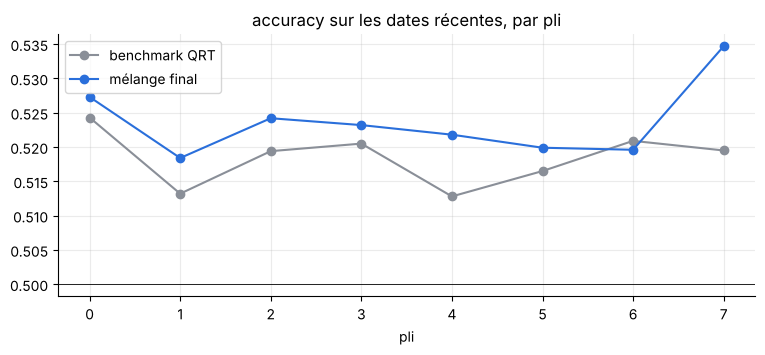

In [4]:
per_fold = pd.DataFrame({'benchmark': refs['benchmark QRT'], 'baseline': refs['baseline'],
                         'logit_alloc': refs['logit_alloc'], 'final': scores['mélange final']}).round(4)
per_fold.index.name = 'pli'
print(per_fold)

g = X.GROUP.to_numpy()
print('\naccuracy du mélange final par groupe (dates récentes) :',
      {gg: round(((oof[(g == gg) & is_recent & ~np.isnan(oof)] > .5) == up[(g == gg) & is_recent & ~np.isnan(oof)]).mean(), 4)
       for gg in [1, 2, 3, 4]})

x = np.arange(len(per_fold))
plt.plot(x, per_fold.benchmark, 'o-', color=GREY, label='benchmark QRT')
plt.plot(x, per_fold.final, 'o-', color=BLUE, label='mélange final')
plt.axhline(.5, color='k', lw=.6)
plt.xticks(x)
plt.xlabel('pli'); plt.title('accuracy sur les dates récentes, par pli')
plt.legend(); plt.show()

Le mélange final fait 52,36 % sur les dates récentes, contre 51,84 % pour le benchmark et 51,73 % pour la baseline.
Il bat le benchmark sur 7 plis sur 8 (t ≈ 3). Le gain est réparti sur trois groupes ; le groupe 3 reste le plus difficile.

## 4. Le coffre-fort

Les 250 dates les plus récentes de la chaîne principale n'ont servi à rien jusqu'ici : ni au choix des features, ni aux réglages.
Chaque modèle est entraîné sur tout le développement, puis évalué une seule fois sur ces dates. C'est la meilleure
estimation dont on dispose de ce qui se passera sur le test.

In [5]:
dev = X.TS.map(ch.set).eq('dev').to_numpy()
lock = X.TS.map(ch.set).eq('lockbox').to_numpy()
acc = lambda p: ((p > .5) == up[lock]).mean()

# références réentraînées sur le développement
lockbox = {'règle naïve': ((X.RET_1.to_numpy()[lock] > 0) == up[lock]).mean()}

def benchmark_features(df):
    df = df.copy()
    for i in [3, 5, 10, 15, 20]:
        df[f'AVERAGE_PERF_{i}'] = df[RET[:i]].mean(axis=1)
        df[f'ALLOCATIONS_AVERAGE_PERF_{i}'] = df.groupby('TS')[f'AVERAGE_PERF_{i}'].transform('mean')
    df['STD_PERF_20'] = df[RET].std(axis=1)
    df['ALLOCATIONS_STD_PERF_20'] = df.groupby('TS')['STD_PERF_20'].transform('mean')
    return df
FB = benchmark_features(X)
bench_cols = [c for c in FB.columns if c not in ('TS', 'ALLOCATION', 'GROUP')]
bench = lgb.train(dict(objective='mse', seed=SEED, verbosity=-1, learning_rate=1e-2, max_depth=3),
                  lgb.Dataset(FB.loc[dev, bench_cols], label=y[dev].to_numpy()), num_boost_round=500)
lockbox['benchmark QRT'] = ((bench.predict(FB.loc[lock, bench_cols]) > 0) == up[lock]).mean()

s = StandardScaler().fit(B[dev])
base_model = LogisticRegression(max_iter=1000).fit(s.transform(B[dev]), up[dev])
lockbox['baseline'] = acc(base_model.predict_proba(s.transform(B[lock]))[:, 1])
alloc_model = LogisticRegression(C=0.003, max_iter=3000).fit(sparse.hstack([s.transform(B[dev]), D[dev]]).tocsr(), up[dev])
lockbox['logit_alloc'] = acc(alloc_model.predict_proba(sparse.hstack([s.transform(B[lock]), D[lock]]).tocsr())[:, 1])

pl, pb = fit_predict(dev, lock)
lockbox['logistique S5'] = acc(pl)
lockbox['LightGBM'] = acc(pb)
lockbox['mélange final'] = acc((pl + pb) / 2)

n_lock = lock.sum()
print(f"coffre-fort : {X.TS[lock].nunique()} dates, {n_lock} lignes ; erreur-type naïve d'une accuracy ≈ {np.sqrt(.25 / n_lock):.4f}")
pd.Series(lockbox, name='accuracy coffre-fort').round(4)

coffre-fort : 250 dates, 65840 lignes ; erreur-type naïve d'une accuracy ≈ 0.0019


règle naïve      0.5110
benchmark QRT    0.5142
baseline         0.5153
logit_alloc      0.5153
logistique S5    0.5166
LightGBM         0.5198
mélange final    0.5198
Name: accuracy coffre-fort, dtype: float64

Sur le coffre-fort, le mélange final fait 51,98 % contre 51,42 % pour le benchmark : **+0,56 point** sur une période jamais
regardée et postérieure à tout le développement. L'écart entre la CV (52,36 %) et le coffre-fort (51,98 %) est de 0,4 point,
exactement la décote mesurée à l'étape b pour le benchmark : le criblage n'a pas gonflé nos scores au-delà de l'effet
déjà connu de la non-stationnarité.

Deux nuances honnêtes :
- l'erreur-type affichée (0,19 point) est une borne basse, car les lignes d'un même jour sont corrélées. L'écart de
  0,56 point avec le benchmark est donc encourageant sans être une certitude. Son sens est le même qu'en CV, ce qui était le vrai test ;
- sur le coffre-fort, le gain vient surtout du LightGBM (51,98 % seul, comme le mélange). L'identité de l'allocation n'apporte
  rien sur cette période (`logit_alloc` = baseline = 51,53 %), et la logistique S5 gagne 0,13 point. Le mélange garde l'avantage
  d'être le meilleur ou à égalité partout, en CV comme sur le coffre-fort : c'est ce qui justifie de le soumettre plutôt qu'un modèle seul.

## 5. Soumission finale

Les deux modèles sont réentraînés sur tout le train, coffre-fort compris : il a rempli son rôle, et pour prédire le test
toute donnée récente est bonne à prendre. Les pairs sont estimés sur tout le train.

In [6]:
everything = np.ones(len(X), dtype=bool)
pl_t, pb_t = fit_predict(everything, None, df_pred=Xt)
p_test = (pl_t + pb_t) / 2

sample = pd.read_csv(utils.find_data_dir() / 'sample_submission.csv', index_col='ROW_ID')
submission = pd.DataFrame({sample.columns[0]: (p_test > .5).astype(int)}, index=Xt.index).loc[sample.index]
submission.index.name = 'ROW_ID'
Path('submissions').mkdir(exist_ok=True)
submission.to_csv('submissions/04_final_blend.csv')
print(submission.shape, '| part de 1 :', round(submission.iloc[:, 0].mean(), 3))

(31870, 1) | part de 1 : 0.584


## Bilan

| | CV dates récentes | coffre-fort |
|---|---|---|
| règle naïve | 51,57 % | 51,10 % |
| benchmark QRT | 51,84 % | 51,42 % |
| baseline logistique | 51,73 % | 51,53 % |
| `logit_alloc` | 51,89 % | 51,53 % |
| **mélange final** | **52,36 %** | **51,98 %** |

En CV, les gains se décomposent ainsi : l'identité de l'allocation (+0,16), puis l'information transversale, c'est-à-dire
les pairs, le groupe et les effets croisés entre groupes (+0,16 de plus), et enfin le mélange avec un boosting (+0,15 de plus).
Sur le coffre-fort, c'est l'information transversale exploitée par le boosting qui tient le mieux.
Ce qui n'a pas marché : changer de modèle seul, pondérer le régime récent, et toutes les variations autour du seul rendement d'hier.